In [1]:
# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

In [2]:
# URL del archivo en el bucket público de AWS
url = "https://hybridge-education-machine-learning-datasets.s3.us-east-1.amazonaws.com/Fraud.csv"
df = pd.read_csv(url)

In [3]:
df.head()

,step,type,amount,nameOrig,oldbalanceOrg,newbalanceOrig,nameDest,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
0,1,PAYMENT,9839.64,C1231006815,170136.0,160296.36,M1979787155,0.0,0.0,0,0
1,1,PAYMENT,1864.28,C1666544295,21249.0,19384.72,M2044282225,0.0,0.0,0,0
2,1,TRANSFER,181.00,C1305486145,181.0,0.00,C553264065,0.0,0.0,1,0
3,1,CASH_OUT,181.00,C840083671,181.0,0.00,C38997010,21182.0,0.0,1,0
4,1,PAYMENT,11668.14,C2048537720,41554.0,29885.86,M1230701703,0.0,0.0,0,0


In [4]:
len(df)

6362620

# ¡¡¡6,362,620 OBSERVACIONES!!!

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [6]:
print(df.shape)

(6362620, 11)


In [7]:
df['isFraud'].value_counts()

isFraud
0    6354407
1       8213
Name: count, dtype: int64

In [8]:
df['isFraud'].value_counts(normalize=True) * 100

isFraud
0    99.870918
1     0.129082
Name: proportion, dtype: float64

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6362620 entries, 0 to 6362619
Data columns (total 11 columns):
 #   Column          Dtype  
---  ------          -----  
 0   step            int64  
 1   type            str    
 2   amount          float64
 3   nameOrig        str    
 4   oldbalanceOrg   float64
 5   newbalanceOrig  float64
 6   nameDest        str    
 7   oldbalanceDest  float64
 8   newbalanceDest  float64
 9   isFraud         int64  
 10  isFlaggedFraud  int64  
dtypes: float64(5), int64(3), str(3)
memory usage: 534.0 MB


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df['type'].value_counts()

type
CASH_OUT    2237500
PAYMENT     2151495
CASH_IN     1399284
TRANSFER     532909
DEBIT         41432
Name: count, dtype: int64

In [13]:
pd.crosstab(df['type'], df['isFraud'])

isFraud,0,1
type,,
CASH_IN,1399284,0
CASH_OUT,2233384,4116
DEBIT,41432,0
PAYMENT,2151495,0
TRANSFER,528812,4097


In [14]:
df.describe()

,step,amount,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest,isFraud,isFlaggedFraud
count,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06,6.362620e+06
mean,2.433972e+02,1.798619e+05,8.338831e+05,8.551137e+05,1.100702e+06,1.224996e+06,1.290820e-03,2.514687e-06
std,1.423320e+02,6.038582e+05,2.888243e+06,2.924049e+06,3.399180e+06,3.674129e+06,3.590480e-02,1.585775e-03
min,1.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
25%,1.560000e+02,1.338957e+04,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00,0.000000e+00
50%,2.390000e+02,7.487194e+04,1.420800e+04,0.000000e+00,1.327057e+05,2.146614e+05,0.000000e+00,0.000000e+00
75%,3.350000e+02,2.087215e+05,1.073152e+05,1.442584e+05,9.430367e+05,1.111909e+06,0.000000e+00,0.000000e+00
max,7.430000e+02,9.244552e+07,5.958504e+07,4.958504e+07,3.560159e+08,3.561793e+08,1.000000e+00,1.000000e+00


In [15]:
df.groupby('isFraud')['amount'].describe()

,count,mean,std,min,25%,50%,75%,max
isFraud,,,,,,,,
0,6354407.0,1.781970e+05,5.962370e+05,0.01,13368.395,74684.72,208364.76,92445516.64
1,8213.0,1.467967e+06,2.404253e+06,0.00,127091.330,441423.44,1517771.48,10000000.00


In [16]:
df.groupby('isFraud')[['oldbalanceOrg', 'newbalanceOrig',
                       'oldbalanceDest', 'newbalanceDest']].mean()

,oldbalanceOrg,newbalanceOrig,oldbalanceDest,newbalanceDest
isFraud,,,,
0,8.328287e+05,855970.228109,1.101421e+06,1.224926e+06
1,1.649668e+06,192392.631836,5.442496e+05,1.279708e+06


In [17]:
pd.crosstab(df['isFlaggedFraud'], df['isFraud'])

isFraud,0,1
isFlaggedFraud,,
0,6354407,8197
1,0,16


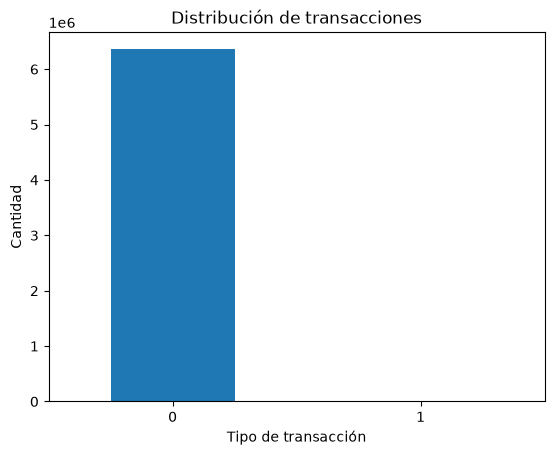

In [18]:
import matplotlib.pyplot as plt

df['isFraud'].value_counts().plot(
    kind='bar',
    title='Distribución de transacciones'
)

plt.xlabel('Tipo de transacción')
plt.ylabel('Cantidad')
plt.xticks(rotation=0)
plt.show()

In [19]:
X = df.drop(columns=['isFraud'])
y = df['isFraud']

In [20]:
print(X.shape)
print(y.shape)

(6362620, 10)
(6362620,)


In [21]:
X = df.drop(columns=[
    'isFraud',
    'nameOrig',
    'nameDest',
    'isFlaggedFraud'
])

print(X.shape)
print(X.head())

(6362620, 7)
   step      type    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   PAYMENT   9839.64       170136.0       160296.36             0.0   
1     1   PAYMENT   1864.28        21249.0        19384.72             0.0   
2     1  TRANSFER    181.00          181.0            0.00             0.0   
3     1  CASH_OUT    181.00          181.0            0.00         21182.0   
4     1   PAYMENT  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  
0             0.0  
1             0.0  
2             0.0  
3             0.0  
4             0.0  


In [22]:
X = pd.get_dummies(X, columns=['type'], drop_first=True)

print(X.shape)
print(X.head())

(6362620, 10)
   step    amount  oldbalanceOrg  newbalanceOrig  oldbalanceDest  \
0     1   9839.64       170136.0       160296.36             0.0   
1     1   1864.28        21249.0        19384.72             0.0   
2     1    181.00          181.0            0.00             0.0   
3     1    181.00          181.0            0.00         21182.0   
4     1  11668.14        41554.0        29885.86             0.0   

   newbalanceDest  type_CASH_OUT  type_DEBIT  type_PAYMENT  type_TRANSFER  
0             0.0          False       False          True          False  
1             0.0          False       False          True          False  
2             0.0          False       False         False           True  
3             0.0           True       False         False          False  
4             0.0          False       False          True          False  


In [23]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(5090096, 10)
(1272524, 10)
(5090096,)
(1272524,)


In [24]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [25]:
print(X_train_scaled.shape)
print(X_test_scaled.shape)

(5090096, 10)
(1272524, 10)


In [26]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(
    class_weight='balanced',
    max_iter=1000,
    random_state=42
)

In [27]:
model.fit(X_train_scaled, y_train)

,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to u

In [28]:
y_pred = model.predict(X_test_scaled)

print(y_pred[:20])

[0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 0 0 0 0]


In [29]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_pred)

print(cm)

[[1206227   64654]
 [     64    1579]]


In [30]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       1.00      0.95      0.97   1270881
           1       0.02      0.96      0.05      1643

    accuracy                           0.95   1272524
   macro avg       0.51      0.96      0.51   1272524
weighted avg       1.00      0.95      0.97   1272524



In [31]:
class_weight='balanced'

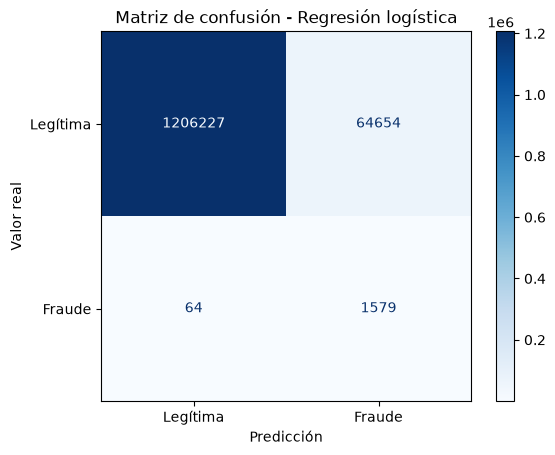

In [33]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['Legítima', 'Fraude']
)

disp.plot(cmap='Blues', values_format='d')

plt.title('Matriz de confusión - Regresión logística')
plt.xlabel('Predicción')
plt.ylabel('Valor real')

plt.show()

In [34]:
y_prob = model.predict_proba(X_test_scaled)

print(y_prob[:10])

[[9.99862404e-001 1.37595869e-004]
 [1.00000000e+000 2.92699035e-087]
 [1.00000000e+000 1.76394542e-104]
 [9.35362737e-001 6.46372626e-002]
 [7.91415988e-001 2.08584012e-001]
 [3.07945723e-001 6.92054277e-001]
 [5.97056902e-001 4.02943098e-001]
 [9.39493166e-001 6.05068345e-002]
 [8.17190766e-001 1.82809234e-001]
 [1.00000000e+000 4.70275146e-105]]


In [35]:
y_prob_fraud = model.predict_proba(X_test_scaled)[:, 1]

print(y_prob_fraud[:20])

[1.37595869e-004 2.92699035e-087 1.76394542e-104 6.46372626e-002
 2.08584012e-001 6.92054277e-001 4.02943098e-001 6.05068345e-002
 1.82809234e-001 4.70275146e-105 8.99871450e-105 4.06664776e-001
 2.86613889e-002 1.14178675e-001 2.97331508e-089 3.40154427e-001
 3.06437961e-104 3.32758302e-002 1.04329646e-104 1.64457441e-005]


In [36]:
umbral = 0.70

y_pred_70 = (y_prob_fraud >= umbral).astype(int)

from sklearn.metrics import confusion_matrix, classification_report

print(confusion_matrix(y_test, y_pred_70))
print(classification_report(y_test, y_pred_70))

[[1240375   30506]
 [    173    1470]]
              precision    recall  f1-score   support

           0       1.00      0.98      0.99   1270881
           1       0.05      0.89      0.09      1643

    accuracy                           0.98   1272524
   macro avg       0.52      0.94      0.54   1272524
weighted avg       1.00      0.98      0.99   1272524



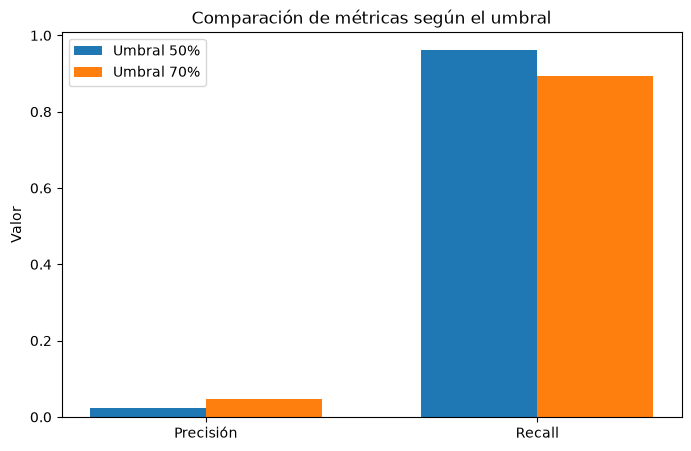

In [37]:
import matplotlib.pyplot as plt

metricas = ['Precisión', 'Recall']

umbral_50 = [0.0239, 0.9610]
umbral_70 = [0.0460, 0.8947]

x = range(len(metricas))
ancho = 0.35

plt.figure(figsize=(8, 5))

plt.bar([i - ancho/2 for i in x], umbral_50,
        ancho, label='Umbral 50%')

plt.bar([i + ancho/2 for i in x], umbral_70,
        ancho, label='Umbral 70%')

plt.xticks(list(x), metricas)
plt.ylabel('Valor')
plt.title('Comparación de métricas según el umbral')
plt.legend()
plt.show()

In [38]:
umbral = 0.60

y_pred_60 = (y_prob_fraud >= umbral).astype(int)

print(confusion_matrix(y_test, y_pred_60))
print(classification_report(y_test, y_pred_60))

[[1225474   45407]
 [    113    1530]]
              precision    recall  f1-score   support

           0       1.00      0.96      0.98   1270881
           1       0.03      0.93      0.06      1643

    accuracy                           0.96   1272524
   macro avg       0.52      0.95      0.52   1272524
weighted avg       1.00      0.96      0.98   1272524



In [39]:
import pandas as pd

comparacion = pd.DataFrame({
    'Umbral': ['50%', '60%', '70%'],
    'Precision': [0.02384, 0.03260, 0.04597],
    'Recall': [0.9610, 0.9312, 0.8947],
    'Falsos positivos': [64654, 45407, 30506],
    'Falsos negativos': [64, 113, 173]
})

print(comparacion)

  Umbral  Precision  Recall  Falsos positivos  Falsos negativos
0    50%    0.02384  0.9610             64654                64
1    60%    0.03260  0.9312             45407               113
2    70%    0.04597  0.8947             30506               173


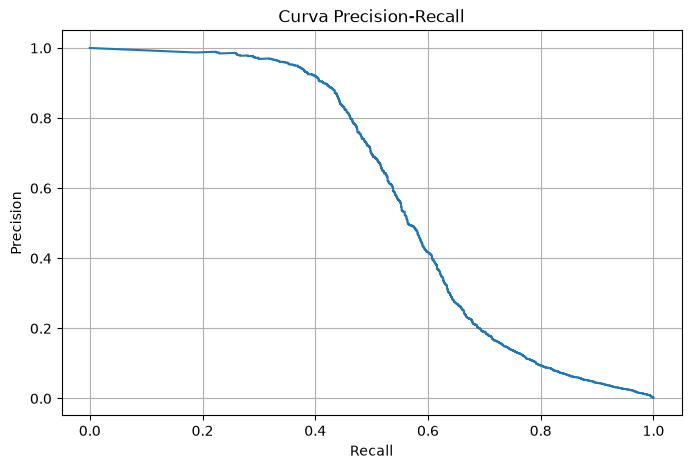

In [40]:
from sklearn.metrics import precision_recall_curve
import matplotlib.pyplot as plt

precision, recall, thresholds = precision_recall_curve(
    y_test,
    y_prob_fraud
)

plt.figure(figsize=(8, 5))

plt.plot(recall, precision)

plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Curva Precision-Recall')

plt.grid()
plt.show()

In [41]:
print("Cantidad de umbrales evaluados:", len(thresholds))

print("Primeros 10 umbrales:")
print(thresholds[:10])

Cantidad de umbrales evaluados: 1272166
Primeros 10 umbrales:
[0.00000000e+000 2.07081453e-285 5.56908909e-282 7.22693168e-282
 5.02883712e-279 4.82535162e-277 1.41600524e-275 1.19123812e-271
 4.30510200e-267 1.42284194e-266]


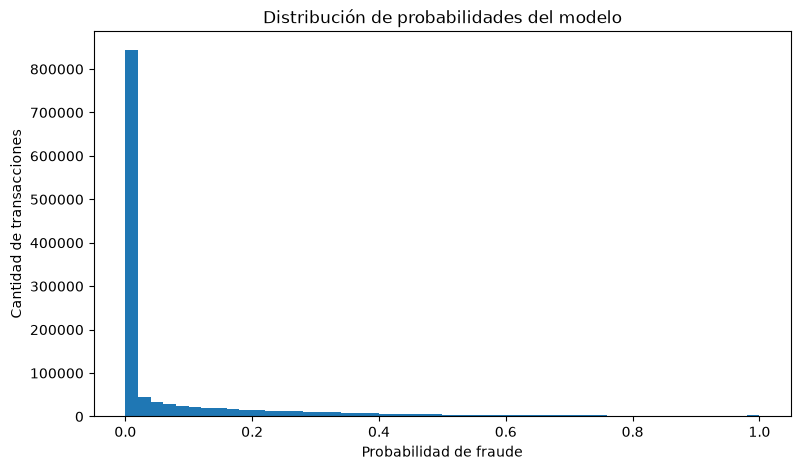

In [42]:
plt.figure(figsize=(9, 5))

plt.hist(y_prob_fraud, bins=50)

plt.xlabel('Probabilidad de fraude')
plt.ylabel('Cantidad de transacciones')
plt.title('Distribución de probabilidades del modelo')

plt.show()